# Research Question 2
At the same rating, does Cons text still distinguish former from current, and what words drive it?

# 0. Setup

In [129]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

seed = 507

# 1. Data Preparation

In [130]:
processed_path = '../data/processed/processed.parquet'

df = pd.read_parquet(processed_path)

In [131]:
df.columns

Index(['firm_id', 'rating', 'former', 'emp_type', 'tenure', 'year', 'date',
       'number of reviews', 'cons', 'job'],
      dtype='str')

In [132]:
columns = ["firm_id", "rating", "former", "number of reviews", "cons"]
new_df = df[columns]

In [133]:
# Create sample
# Firms must have reviews from at least 10 current and at least 10 former employees

sample_df = new_df.groupby("firm_id").filter(
    lambda g: (g["former"] == 1).sum() >= 10 and (g["former"] == 0).sum() >= 10
)

In [134]:
# Split sample to train/validation/test (64/16/20)
def group_split(df, col, test_size, seed):
    gss = GroupShuffleSplit(n_splits=1, test_size=test_size, random_state=seed)
    a, b = next(gss.split(df, groups=df[col]))
    return df.iloc[a], df.iloc[b]

trainval, test = group_split(sample_df, "firm_id", 0.20, seed)
train, val = group_split(trainval, "firm_id", 0.20, seed)

In [135]:
print(f"Train: {round(len(train)/len(sample_df)*100, 2)}%, Validation: {round(len(val)/len(sample_df)*100, 2)}%, Test: {round(len(test)/len(sample_df)*100, 2)}%")

Train: 63.01%, Validation: 17.29%, Test: 19.69%


In [136]:
print(f"Average Ratings\n\nTrain: {round(train.rating.mean(), 2)}, Validation: {round(val.rating.mean(), 2)}, Test: {round(test.rating.mean(), 2)}")

Average Ratings

Train: 3.71, Validation: 3.72, Test: 3.7


# 2. Experiment

In [137]:
# Check the most frequent words in Cons text

s = train.sample(300000, random_state=seed)

former_text = s[s["former"] == 1]["cons"].fillna("")
current_text = s[s["former"] == 0]["cons"].fillna("")

# Include phrases like "I left", "I was there"
cv = CountVectorizer(ngram_range=(1, 3), min_df=20, binary=True, token_pattern=r"(?u)\b\w+\b")
cv.fit(s["cons"].fillna(""))

former_count = cv.transform(former_text).sum(axis=0).tolist()[0]
current_count = cv.transform(current_text).sum(axis=0).tolist()[0]

table = pd.DataFrame({
    "phrase": cv.get_feature_names_out(),
    "former_pct": [c / len(former_text) * 100 for c in former_count],
    "current_pct": [c / len(current_text) * 100 for c in current_count],
})

In [138]:
table["ratio"] = (table["former_pct"] + 0.01) / (table["current_pct"] + 0.01)

former_side = table.sort_values("ratio", ascending=False).head(20)[["phrase", "ratio"]]
current_side = table.sort_values("ratio").head(20)[["phrase", "ratio"]]

pd.concat(
    [former_side.reset_index(drop=True), current_side.reset_index(drop=True)],
    axis=1,
    keys=["former", "current"],
)

former                  current          
            phrase     ratio         phrase     ratio
0           i left  7.403431       till now  0.121856
1   management was  6.960354         so far  0.159760
2    managers were  6.786075    none so far  0.171595
3      i was there  6.737475        any yet  0.176684
4   i worked there  6.608852       cons yet  0.179507
5         i worked  5.930688       so far i  0.181642
6        was there  5.927409        none so  0.190790
7      i worked at  5.776269        i haven  0.194643
8      manager was  5.722242      i haven t  0.195347
9      didn t care  5.708975      as of now  0.197334
10    was horrible  5.693298         of now  0.202988
11       felt like  5.673654          far i  0.203351
12      there were  5.608762  cons till now  0.205520
13    was terrible  5.464545   any cons yet  0.209153
14       there was  5.387699          as of  0.210278
15     there was a  5.348210  haven t found  0.213930
16          wasn t  5.273915      cons till  0.219040
17            wasn  5.273915    cons so far  0.219585
18       were very  5.098594  nothing as of  0.232071
19        was very  5.036820      till date  0.232219

## Signals

| former                            | current   |
| --------------------------------- | --------------------------------- |
| i left, was working, i worked, i was there, i worked there, was there, i worked at, my time there, i quit, i was working | till now, so far i, so far, cons yet, far i, any cons yet, as of now, of now, cons so, as of, cons so far, none so far, as of yet, none so, any yet, none as of, any so far |

In [139]:
# Remove signals
remove_phrases = [
    "i worked there", "i was there", "i worked at", "my time there", "i was working",
    "any cons yet", "cons so far", "none so far", "none as of", "any so far", "so far i", "as of now", "as of yet",
    "i left", "was working", "i worked", "was there", "i quit",
    "till now", "so far", "cons yet", "far i", "of now", "cons so", "as of", "none so", "any yet",
]
pattern = r"\b(" + "|".join(remove_phrases) + r")\b"

def clean(text):
    return text.fillna("").str.replace(pattern, " ", case=False, regex=True)

train["cons_clean"] = clean(train["cons"])
val["cons_clean"] = clean(val["cons"])
test["cons_clean"] = clean(test["cons"])

In [140]:
# Save
train.to_parquet("../data/processed/rq2/train.parquet", index=False)
val.to_parquet("../data/processed/rq2/validation.parquet", index=False)
test.to_parquet("../data/processed/rq2/test.parquet", index=False)

In [141]:
# AUC Score
def firm_auc_score(test_data, y_pred):
    df = test_data.copy()
    df["pred"] = y_pred
    records = []

    for (firm, rating), g in df.groupby(["firm_id", "rating"]):
        f_preds = np.array(g[g["former"] == 1]["pred"])
        c_preds = np.array(g[g["former"] == 0]["pred"])

        if len(f_preds) == 0 or len(c_preds) == 0:
            continue

        diff = f_preds[:, np.newaxis] - c_preds
        wins = (diff > 0).sum() + 0.5 * (diff == 0).sum()
        pairs = len(f_preds) * len(c_preds)

        records.append({"firm_id": firm, "wins": wins, "pairs": pairs})

    result = pd.DataFrame(records)
    wins_sum = result.groupby("firm_id")["wins"].sum()
    pairs_sum = result.groupby("firm_id")["pairs"].sum()
    firm_auc = wins_sum / pairs_sum
    return firm_auc

def calculate_auc_score(test_data, y_pred):
    return firm_auc_score(test_data, y_pred).mean()

In [142]:
def bootstrap_ci_rq2(firm_values, seed, n=2000):
    rng = np.random.default_rng(seed)
    x = firm_values.to_numpy()
    means = [rng.choice(x, size=len(x)).mean() for _ in range(n)]
    return np.percentile(means, [2.5, 97.5])

## 2.1 Word-Count

In [143]:
train["word_count"] = train["cons_clean"].apply(lambda x: len(str(x).split()))
val["word_count"] = val["cons_clean"].apply(lambda x: len(str(x).split()))
test["word_count"] = test["cons_clean"].apply(lambda x: len(str(x).split()))

In [144]:
# Scale inputs since the range of words is large
ss = StandardScaler()

X_train_scaled = ss.fit_transform(pd.DataFrame(train.word_count))
X_val_scaled = ss.transform(pd.DataFrame(val.word_count))
X_test_scaled = ss.transform(pd.DataFrame(test.word_count))

In [145]:
lr_wc = LogisticRegression(max_iter=1000, random_state=seed)
model_wc = lr_wc.fit(X_train_scaled, train["former"])

y_pred_wc = model_wc.predict_proba(X_test_scaled)[:, 1] # Probability of Class 1 (former)
firm_auc_wc = firm_auc_score(test, y_pred_wc)
lo_wc, hi_wc = bootstrap_ci_rq2(firm_auc_wc, seed)
auc_wc = calculate_auc_score(test, y_pred_wc)

print(f"Word Count AUC: {auc_wc:.3f} [{lo_wc:.3f}, {hi_wc:.3f}]")

Word Count AUC: 0.499 [0.495, 0.503]


## 2.2 TF-IDF

For term $t$ in review $d$ (scikit-learn definition, [User Guide: Tf–idf term weighting](https://scikit-learn.org/stable/modules/feature_extraction.html#tfidf-term-weighting)):
$$
\text{tf-idf}(t,d) = \text{tf}(t,d) \times \left(\ln\frac{1+n}{1+\text{df}(t)} + 1\right)
$$

## 2.2.1 Experiment

In [146]:
vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=10) # We ignore words that rarely show up

X_train_tfidf = vectorizer.fit_transform(train["cons_clean"])
X_val_tfidf = vectorizer.transform(val["cons_clean"])
X_test_tfidf = vectorizer.transform(test["cons_clean"])

In [156]:
c_list = [0.01, 0.1, 1, 10]
auc_tfidf_list = []

for c in c_list:
    lr_tfidf = LogisticRegression(C=c, max_iter=1000, random_state=seed)
    model_tfidf = lr_tfidf.fit(X_train_tfidf, train["former"])

    y_pred_tfidf = model_tfidf.predict_proba(X_val_tfidf)[:, 1] # Probability of Class 1 (former)
    auc_tfidf = calculate_auc_score(val, y_pred_tfidf)
    print(f"C: {c} TF-IDF AUC: {auc_tfidf:.3f}\n")
    auc_tfidf_list.append([c, auc_tfidf])

best_c_tfidf, best_auc_tfidf = max(auc_tfidf_list, key=lambda x: x[1])
print(f"================================\nBest C: {best_c_tfidf} TF-IDF AUC: {best_auc_tfidf:.3f}")

C: 0.01 TF-IDF AUC: 0.616

C: 0.1 TF-IDF AUC: 0.630

C: 1 TF-IDF AUC: 0.629

C: 10 TF-IDF AUC: 0.621

Best C: 0.1 TF-IDF AUC: 0.630


In [157]:
lr_tfidf = LogisticRegression(C=best_c_tfidf, max_iter=1000, random_state=seed)
model_tfidf = lr_tfidf.fit(X_train_tfidf, train["former"])

y_pred_tfidf = model_tfidf.predict_proba(X_test_tfidf)[:, 1]
firm_auc_tfidf = firm_auc_score(test, y_pred_tfidf)
lo_tfidf, hi_tfidf = bootstrap_ci_rq2(firm_auc_tfidf, seed)
auc_tfidf = calculate_auc_score(test, y_pred_tfidf)

print(f"TF-IDF AUC: {auc_tfidf:.3f} [{lo_tfidf:.3f}, {hi_tfidf:.3f}]")

TF-IDF AUC: 0.633 [0.629, 0.637]


In [158]:
lo_diff, hi_diff = bootstrap_ci_rq2(firm_auc_tfidf - firm_auc_wc, seed)
print(f"95% Confidence Interval for the difference between Word-Count model and TF-IDF model is: [{lo_diff:.3f}, {hi_diff:.3f}]")

95% Confidence Interval for the difference between Word-Count model and TF-IDF model is: [0.128, 0.140]


In [159]:
# Save firm_auc_tfidf to compare it with firm_auc_se (sentence embedding)
firm_auc_tfidf.to_frame("auc").to_parquet("../data/processed/rq2/firm_auc_tfidf.parquet")

### 2.2.2 Check important features

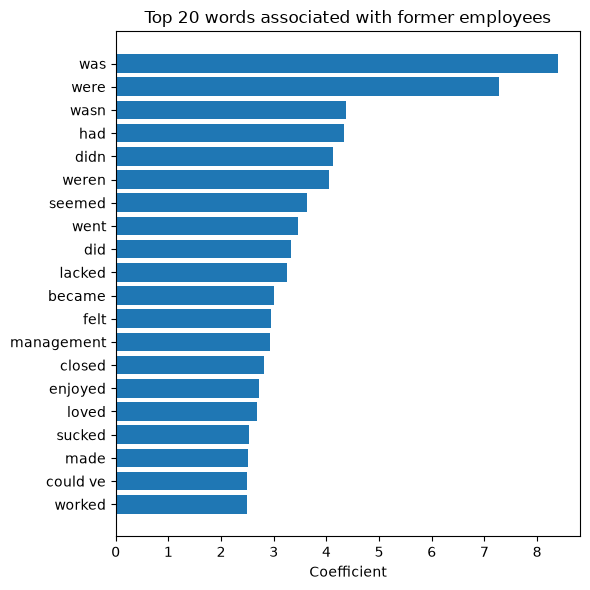

In [160]:
feature_names = vectorizer.get_feature_names_out()
coefficients = model_tfidf.coef_[0]

importance_df = pd.DataFrame(
    {"word": feature_names, "coefficient": coefficients}
).sort_values(by="coefficient", ascending=False)

top20 = importance_df.head(20).iloc[::-1]

plt.figure(figsize=(6, 6))
plt.barh(top20["word"], top20["coefficient"])
plt.xlabel("Coefficient")
plt.title("Top 20 words associated with former employees")
plt.tight_layout()
plt.show()

# 3. Result

In [165]:
result = pd.DataFrame([
    ["Word Count", 0.499, 0.495, 0.503],
    ["TF-IDF", 0.633, 0.629, 0.637],
    ["Sentence Embedding", 0.605 ,0.601, 0.609]
], columns=["Model", "AUC", "Low", "High"]
)

result

,Model,AUC,Low,High
0,Word Count,0.499,0.495,0.503
1,TF-IDF,0.633,0.629,0.637
2,Sentence Embedding,0.605,0.601,0.609


In [166]:
diff = pd.DataFrame([
    ["TF-IDF - Word Count", 0.128, 0.140],
    ["Sentence Embedding - TF-IDF", -0.032, -0.025],
], columns=["Difference", "Low", "High"]
)

diff

,Difference,Low,High
0,TF-IDF - Word Count,0.128,0.140
1,Sentence Embedding - TF-IDF,-0.032,-0.025


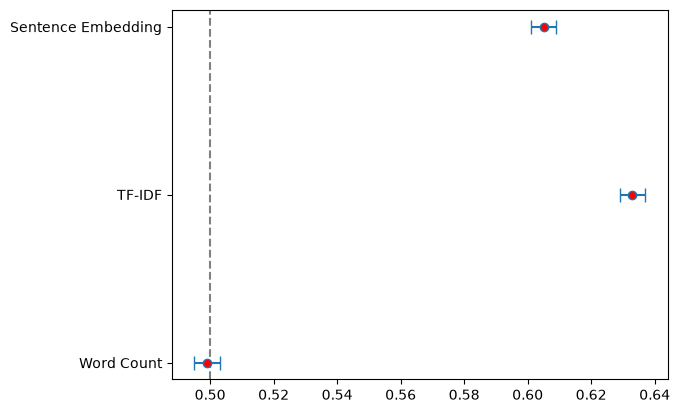

In [167]:
plt.errorbar(
    x=result["AUC"],
    y=result["Model"],
    xerr=[result["AUC"] - result["Low"], result["High"] - result["AUC"]],
    fmt="o",
    capsize=5,
    mfc="red"
    )
plt.axvline(0.50, linestyle="--", color="gray")

plt.show()


Results show that Cons words are more strongly associated with status information than texts’ length. The 95% confidence interval for the TF-IDF model’s AUC (0.629 to 0.637) excludes 0.5, supporting H2a. TF-IDF model measures how often a word appears in Cons texts, so the result that the 95% confidence interval of the difference between the TF-IDF model and the Word Count model is positive (0.128 to 0.140) means word use carries some information to distinguish whether the review is written by a former or current employee. “Management” ranks 13th among the Top 20 words of the TF-IDF model, which supports H2b, although its rank is sensitive to the regularization strength. However, most of the Top 20 words are past-tense words such as “was” and “were”. This also suggests that verb tense may be one of the main cues behind the AUC, rather than the topics employees write about.